# AgriSignal: exploring the data

Before building any model I want to know:

1. Does the satellite data behave the way crops should (wheat in winter, rice in the monsoon)?
2. How do wheat and paddy prices move, and how much of that is just the calendar?
3. Which signals (crop health, rain, heat, government stocks, policy) relate to price changes 1 to 3 months later?

The data is the national monthly table from `src/build_national.py`, January 2005 to September 2026. Crop health (NDVI), rainfall and air temperature (ERA5-Land) are averaged over the main wheat states (204 districts) and rice states (222 districts), weighted by each district's farmland. Prices are the all-India wholesale price index (WPI). Stocks are the government's central pool on the 1st of each month. Before April 2012 the paddy price is the rice index, because WPI had no paddy item then.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

COLORS = {"wheat": "#c28a00", "paddy": "#2a7f62"}
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

national = pd.read_csv(Path("..") / "data" / "processed" / "national_monthly.csv")
national["date"] = pd.to_datetime(national["month"])
national["calendar_month"] = national["date"].dt.month
national["year"] = national["date"].dt.year
national = national.sort_values(["crop", "date"]).reset_index(drop=True)

# Anomaly = value minus the average for that crop and calendar month.
for column in ["ndvi", "rainfall_mm", "tmax_c"]:
    normal = national.groupby(["crop", "calendar_month"])[column].transform("mean")
    national[f"{column}_anomaly"] = national[column] - normal

national.head()

,crop,month,ndvi,rainfall_mm,tmean_c,tmax_c,wpi,wpi_series,all_commodities,food_articles,...,msp_rs_per_qtl,export_ban,stock_limit,districts,date,calendar_month,year,ndvi_anomaly,rainfall_mm_anomaly,tmax_c_anomaly
0,paddy,2005-01,0.4726,28.3,18.40,26.82,35.34,2004-05 linked (rice),42.38,28.16,...,560.0,0,0,222,2005-01-01,1,2005,-0.035155,14.350000,-0.851818
1,paddy,2005-02,0.4892,16.9,21.39,32.34,35.62,2004-05 linked (rice),42.42,28.13,...,560.0,0,0,222,2005-02-01,2,2005,-0.027545,1.472727,0.408636
2,paddy,2005-03,0.3894,29.4,26.20,36.12,35.66,2004-05 linked (rice),42.54,28.22,...,560.0,0,0,222,2005-03-01,3,2005,-0.040209,8.540909,-0.804091
3,paddy,2005-04,0.2906,23.1,29.65,39.42,35.80,2004-05 linked (rice),43.09,28.94,...,560.0,0,0,222,2005-04-01,4,2005,-0.036091,0.381818,-0.931364
4,paddy,2005-05,0.2728,32.0,32.13,42.06,35.80,2004-05 linked (rice),43.01,28.91,...,560.0,0,0,222,2005-05-01,5,2005,-0.044823,-19.250000,0.372273


## 1. Seasonal cycle of crop health

Wheat is sown in November and harvested in April, so the wheat states should be green from December to February. Rice grows in the monsoon, so the rice states should peak around August and September.

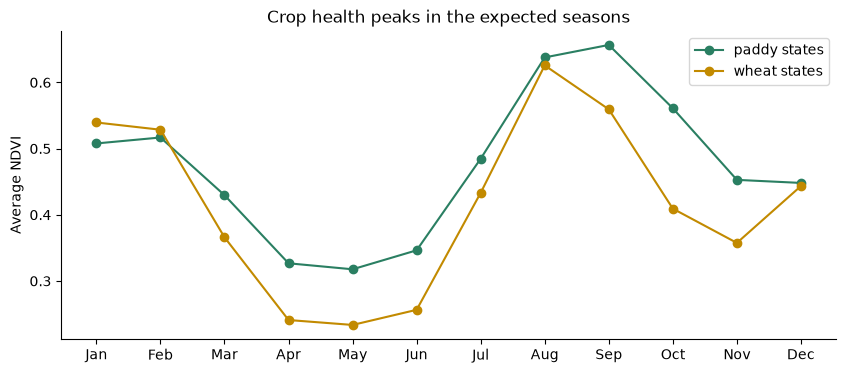

In [2]:
seasonal = national.groupby(["calendar_month", "crop"])["ndvi"].mean().unstack()

fig, ax = plt.subplots()
for crop in seasonal.columns:
    ax.plot(seasonal.index, seasonal[crop], marker="o", color=COLORS[crop], label=f"{crop} states")
ax.set_xticks(range(1, 13), MONTH_NAMES)
ax.set_ylabel("Average NDVI")
ax.set_title("Crop health peaks in the expected seasons")
ax.legend()
plt.show()

The wheat states also turn green in August. That is the kharif crop (rice, soybean, cotton) growing in the same states, not wheat.

## 2. Crop health compared with normal

Raw NDVI goes up and down every year with the seasons. To see whether crops are doing better or worse than usual, I subtract the average for that calendar month (the anomaly).

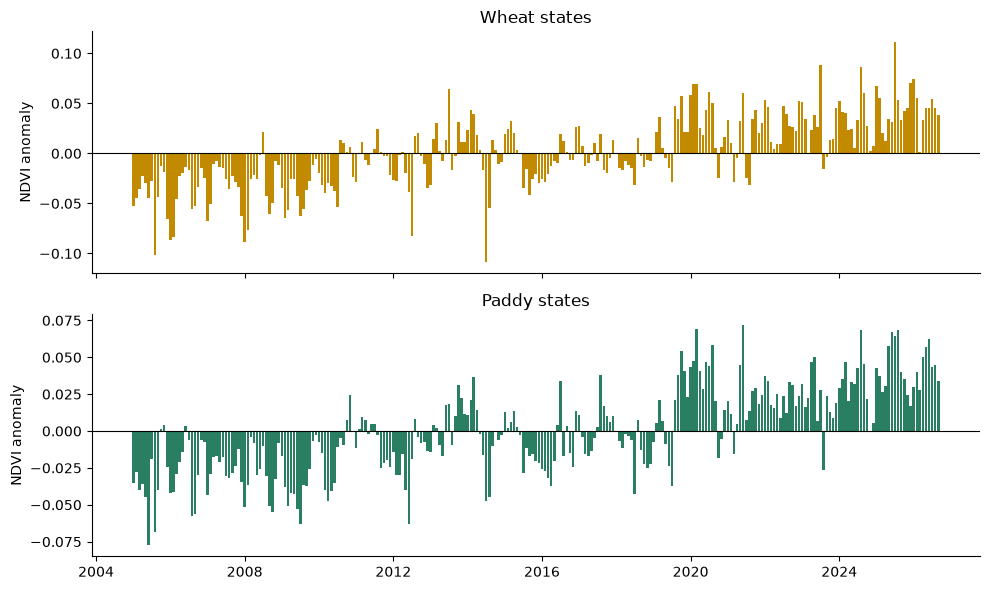

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
crop,,,,,,,,,,,,,,,,,,,,,
paddy,-0.034,-0.026,-0.026,-0.029,-0.035,-0.015,-0.007,-0.020,0.006,-0.004,...,0.003,-0.012,0.011,0.032,0.021,0.023,0.020,0.032,0.043,0.043
wheat,-0.042,-0.039,-0.031,-0.033,-0.038,-0.020,-0.003,-0.017,0.010,-0.005,...,0.000,-0.009,0.016,0.033,0.015,0.029,0.026,0.034,0.048,0.044


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, crop in zip(axes, ["wheat", "paddy"]):
    data = national[national["crop"] == crop]
    ax.bar(data["date"], data["ndvi_anomaly"], width=25, color=COLORS[crop])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("NDVI anomaly")
    ax.set_title(f"{crop.title()} states")
plt.tight_layout()
plt.show()

national.groupby(["year", "crop"])["ndvi_anomaly"].mean().unstack().round(3).T

## 3. Heat stress in the wheat states

Wheat fills its grain in March. A hot March shrinks the grain even if the plants still look green, which NDVI cannot see. This is the hottest air temperature reached in March, averaged over the wheat districts and compared with an average March. (It comes from the ERA5-Land reanalysis: the MODIS land temperature I tried first drifts cooler after 2020 as the satellites' orbits change.)

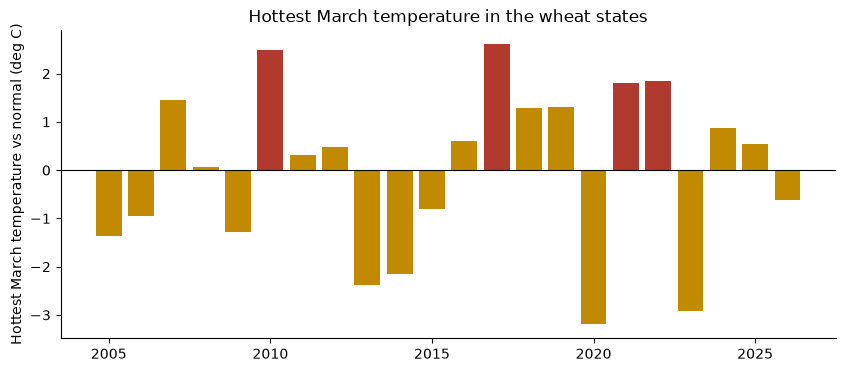

,tmax_c,tmax_c_anomaly,ndvi_anomaly
year,,,
2017,39.43,2.60,-0.01
2010,39.32,2.49,-0.04
2022,38.67,1.84,0.01
2021,38.62,1.79,-0.03
2007,38.27,1.44,-0.01


In [4]:
wheat = national[national["crop"] == "wheat"]
march = wheat[wheat["calendar_month"] == 3].set_index("year")

fig, ax = plt.subplots()
colors = ["#b03a2e" if value > 1.5 else COLORS["wheat"] for value in march["tmax_c_anomaly"]]
ax.bar(march.index, march["tmax_c_anomaly"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Hottest March temperature vs normal (deg C)")
ax.set_title("Hottest March temperature in the wheat states")
plt.show()

march[["tmax_c", "tmax_c_anomaly", "ndvi_anomaly"]].round(2).sort_values("tmax_c_anomaly", ascending=False).head(5)

## 4. Monsoon rainfall by year

Total June to September rainfall in the rice states.

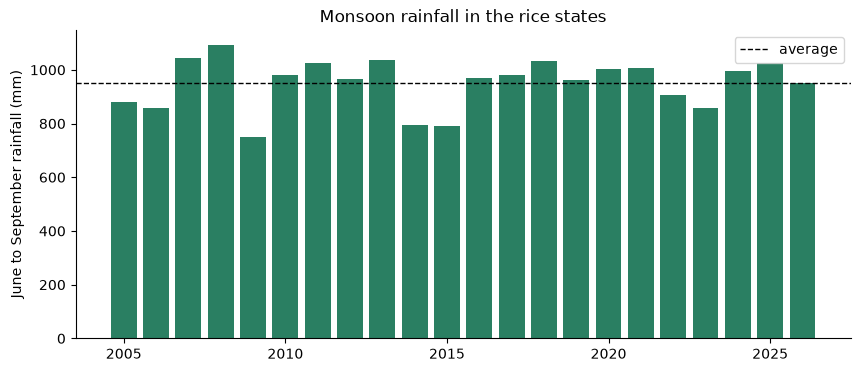

year
2009    749.0
2015    793.0
2014    794.0
2023    858.0
2006    858.0
Name: rainfall_mm, dtype: float64

In [5]:
paddy = national[national["crop"] == "paddy"]
monsoon = paddy[paddy["calendar_month"].between(6, 9)].groupby("year")["rainfall_mm"].sum()

fig, ax = plt.subplots()
ax.bar(monsoon.index, monsoon, color=COLORS["paddy"])
ax.axhline(monsoon.mean(), color="black", linestyle="--", linewidth=1, label="average")
ax.set_ylabel("June to September rainfall (mm)")
ax.set_title("Monsoon rainfall in the rice states")
ax.legend()
plt.show()
monsoon.sort_values().head(5).round(0)

## 5. Prices and export bans

The shaded periods are export bans on that crop. Governments ban exports when domestic prices are rising, so a ban is partly a sign of a price problem and partly a fix for it.

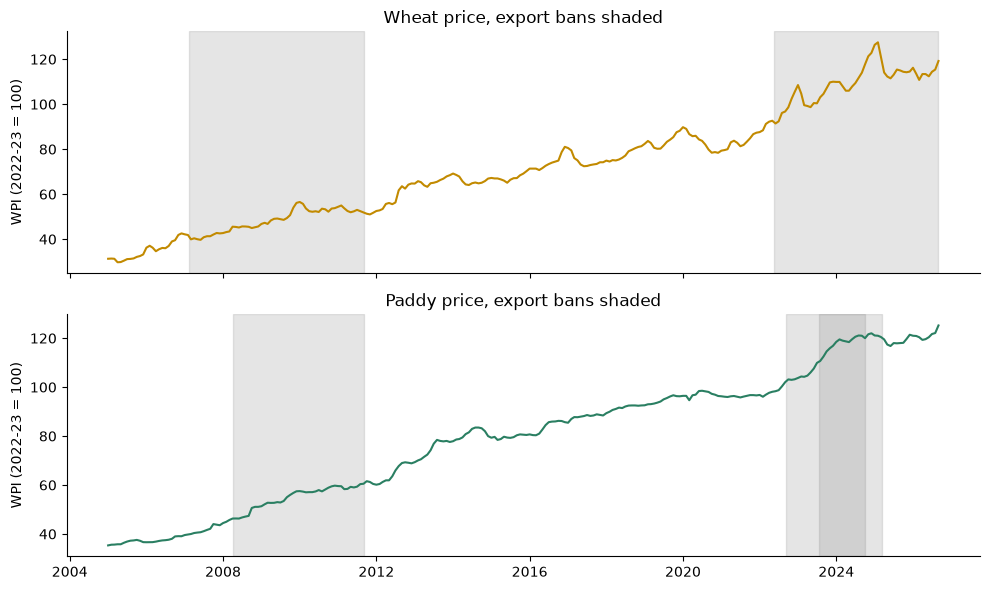

In [6]:
events = pd.read_csv(Path("..") / "data" / "raw" / "policy_events.csv", parse_dates=["start", "end"])
end_of_data = national["date"].max()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, crop in zip(axes, ["wheat", "paddy"]):
    data = national[national["crop"] == crop]
    ax.plot(data["date"], data["wpi"], color=COLORS[crop])
    bans = events[(events["crop"] == crop) & events["event"].str.contains("export_ban")]
    for ban in bans.itertuples():
        ax.axvspan(ban.start, ban.end if pd.notna(ban.end) else end_of_data, color="grey", alpha=0.2)
    ax.set_ylabel("WPI (2022-23 = 100)")
    ax.set_title(f"{crop.title()} price, export bans shaded")
plt.tight_layout()
plt.show()

## 6. Government stocks

The central pool stock on the 1st of each month. Wheat jumps every May when the government buys the new harvest, then drains through the year. Low stocks leave less room to cool prices by selling grain.

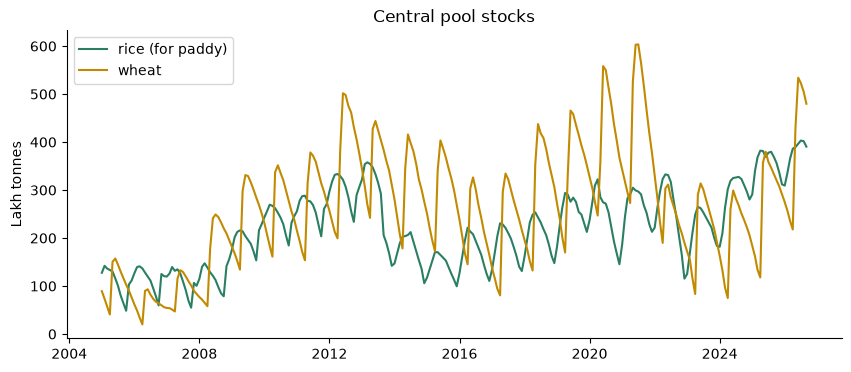

In [7]:
fig, ax = plt.subplots()
for crop, data in national.groupby("crop"):
    label = "rice (for paddy)" if crop == "paddy" else crop
    ax.plot(data["date"], data["stock_lakh_t"], color=COLORS[crop], label=label)
ax.set_ylabel("Lakh tonnes")
ax.set_title("Central pool stocks")
ax.legend()
plt.show()

## 7. How much of the up and down is just the calendar?

If prices almost always rise in some months and fall in others, a model that only knows the month can already look accurate. Any other signal has to beat that.

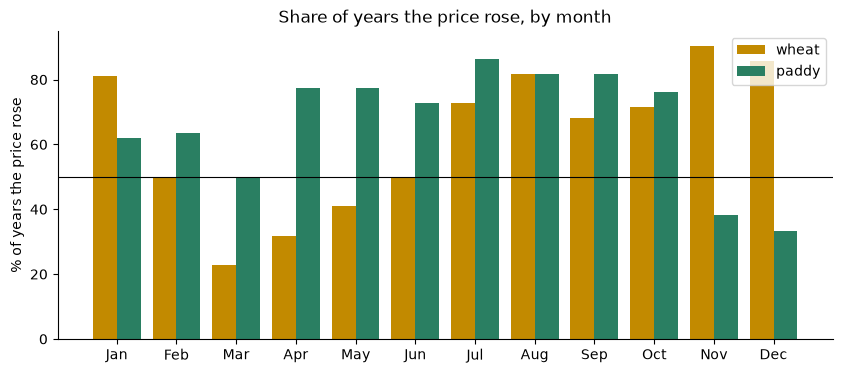

crop
paddy    0.67
wheat    0.62
Name: price_change, dtype: float64

In [8]:
national["price_change"] = national.groupby("crop")["wpi"].pct_change() * 100
changes = national.dropna(subset=["price_change"])
share_up = changes.assign(went_up=changes["price_change"] > 0).groupby(["calendar_month", "crop"])["went_up"].mean().unstack()

fig, ax = plt.subplots()
width = 0.4
for offset, crop in zip([-width / 2, width / 2], ["wheat", "paddy"]):
    ax.bar(share_up.index + offset, share_up[crop] * 100, width, color=COLORS[crop], label=crop)
ax.axhline(50, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13), MONTH_NAMES)
ax.set_ylabel("% of years the price rose")
ax.set_title("Share of years the price rose, by month")
ax.legend()
plt.show()

changes.groupby("crop")["price_change"].apply(lambda s: (s > 0).mean()).round(2)

## 8. Which signals relate to later price changes?

For each month I compare a set of signals with the price change over the next 1, 2 and 3 months. To keep the calendar from faking a relationship, the price change is measured against the usual change for that calendar month. The signals:

- **NDVI, rain and temperature anomalies**: crop conditions compared with normal (temperature is the hottest of the month).
- **Stock change**: central pool stock compared with 12 months earlier (%).
- **Price momentum**: the crop's own price change over the last month.
- **Food inflation**: change in the food articles index over the last month.
- **MSP change**: the support price in force compared with 12 months earlier (%).
- **Export ban**: 1 if an export ban was in force.

With about 255 months, a correlation needs to be bigger than about 0.12 (either sign) before it is unlikely to be chance, and less than that for 2 and 3 months ahead, because those windows overlap.

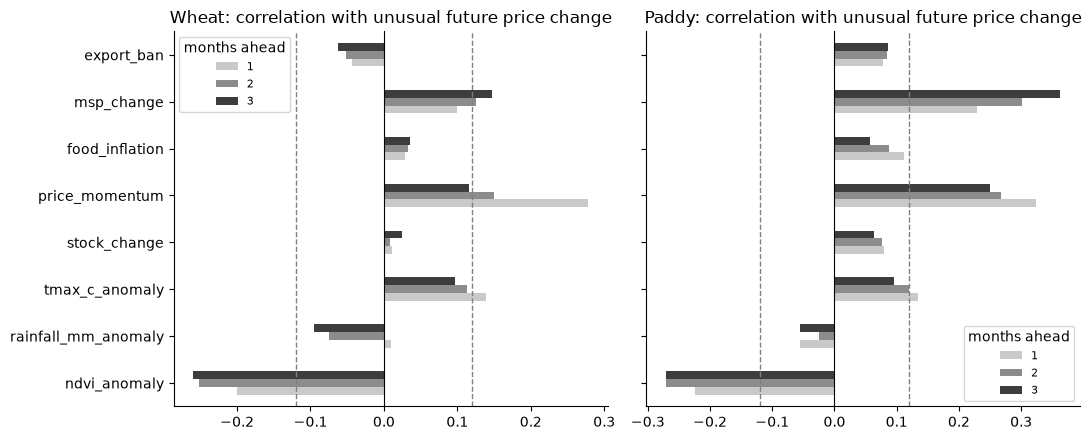

ndvi_anomaly  rainfall_mm_anomaly  tmax_c_anomaly  \
crop  months_ahead                                                      
paddy 1                   -0.225               -0.056           0.134   
      2                   -0.271               -0.024           0.119   
      3                   -0.270               -0.056           0.096   
wheat 1                   -0.201                0.009           0.139   
      2                   -0.252               -0.074           0.113   
      3                   -0.259               -0.095           0.097   

                    stock_change  price_momentum  food_inflation  msp_change  \
crop  months_ahead                                                             
paddy 1                    0.079           0.324           0.111       0.230   
      2                    0.077           0.268           0.088       0.302   
      3                    0.064           0.249           0.056       0.363   
wheat 1                    0.011           0.278           0.029       0.099   
      2                    0.008           0.150           0.033       0.126   
      3                    0.025           0.115           0.036       0.147   

                    export_ban  
crop  months_ahead              
paddy 1                  0.077  
      2                  0.084  
      3                  0.086  
wheat 1                 -0.043  
      2                 -0.051  
      3                 -0.062

In [9]:
def add_signals(data):
    data = data.copy()
    data["stock_change"] = data["stock_lakh_t"].pct_change(12) * 100
    data["price_momentum"] = data["wpi"].pct_change() * 100
    data["food_inflation"] = data["food_articles"].pct_change() * 100
    data["msp_change"] = data["msp_rs_per_qtl"].pct_change(12) * 100
    return data

SIGNALS = ["ndvi_anomaly", "rainfall_mm_anomaly", "tmax_c_anomaly", "stock_change",
           "price_momentum", "food_inflation", "msp_change", "export_ban"]

rows = []
for crop, data in national.groupby("crop"):
    data = add_signals(data)
    for months_ahead in [1, 2, 3]:
        future = (data["wpi"].shift(-months_ahead) / data["wpi"] - 1) * 100
        unusual = future - future.groupby(data["calendar_month"]).transform("mean")
        row = {"crop": crop, "months_ahead": months_ahead}
        row.update({signal: data[signal].corr(unusual) for signal in SIGNALS})
        rows.append(row)
signal_corr = pd.DataFrame(rows).set_index(["crop", "months_ahead"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, crop in zip(axes, ["wheat", "paddy"]):
    signal_corr.loc[crop].T.plot.barh(ax=ax, color=["#c9c9c9", "#8c8c8c", "#3d3d3d"])
    ax.axvline(0, color="black", linewidth=0.8)
    for line in [0.12, -0.12]:
        ax.axvline(line, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"{crop.title()}: correlation with unusual future price change")
    ax.legend(title="months ahead", fontsize=8)
plt.tight_layout()
plt.show()
signal_corr.round(3)

## 9. Checking the trend and the rice years

Two things could create a false relationship. NDVI drifts upward over the years (better farming, or slow satellite drift), so I repeat the NDVI test with a straight-line trend removed. And before 2012 the paddy price is really the rice index, so I repeat the paddy tests from 2012 only.

In [10]:
rows = []
for crop, data in national.groupby("crop"):
    data = add_signals(data)
    step = np.arange(len(data))
    slope, intercept = np.polyfit(step, data["ndvi_anomaly"], 1)
    data["ndvi_detrended"] = data["ndvi_anomaly"] - (slope * step + intercept)
    for since in [2005, 2012]:
        part = data[data["year"] >= since]
        future = (part["wpi"].shift(-2) / part["wpi"] - 1) * 100
        unusual = future - future.groupby(part["calendar_month"]).transform("mean")
        row = {"crop": crop, "since": since, "ndvi_trend_per_year": slope * 12,
               "ndvi_detrended": part["ndvi_detrended"].corr(unusual)}
        row.update({signal: part[signal].corr(unusual) for signal in SIGNALS})
        rows.append(row)
pd.DataFrame(rows).set_index(["crop", "since"]).round(3)

ndvi_trend_per_year  ndvi_detrended  ndvi_anomaly  \
crop  since                                                      
paddy 2005                 0.004          -0.170        -0.271   
      2012                 0.004          -0.148        -0.234   
wheat 2005                 0.004          -0.248        -0.252   
      2012                 0.004          -0.275        -0.277   

             rainfall_mm_anomaly  tmax_c_anomaly  stock_change  \
crop  since                                                      
paddy 2005                -0.024           0.119         0.077   
      2012                -0.046           0.128        -0.012   
wheat 2005                -0.074           0.113         0.008   
      2012                -0.018           0.122        -0.002   

             price_momentum  food_inflation  msp_change  export_ban  
crop  since                                                          
paddy 2005            0.268           0.088       0.302       0.084  
      2012            0.363           0.082       0.268       0.071  
wheat 2005            0.150           0.033       0.126      -0.051  
      2012            0.184           0.017       0.066      -0.008

## 10. Case study: the 2022 heatwave

In March 2022 an early heatwave hit north India just before the wheat harvest. Wheat prices rose and the government banned wheat exports in May.

In [11]:
wheat_2022 = national[(national["crop"] == "wheat")].set_index("month")
wheat_2022.loc["2021-12":"2022-07", ["ndvi_anomaly", "tmax_c_anomaly", "stock_lakh_t", "wpi", "price_change", "export_ban"]].round(2)

,ndvi_anomaly,tmax_c_anomaly,stock_lakh_t,wpi,price_change,export_ban
month,,,,,,
2021-12,0.03,-1.43,378.53,87.33,0.74,0
2022-01,0.05,-2.35,330.12,87.60,0.31,0
2022-02,0.05,-1.42,282.73,88.40,0.91,0
2022-03,0.01,1.84,234.00,91.22,3.19,0
2022-04,0.00,1.16,189.90,92.23,1.11,0
2022-05,0.01,0.46,303.46,92.65,0.46,1
2022-06,0.01,0.27,311.42,91.43,-1.32,1
2022-07,0.05,-1.34,285.10,92.39,1.05,1


## What I found

**The data behaves like real crops and real weather.** Wheat states are greenest in January and February and turn brown at the April harvest; rice states peak in August and September. The weakest monsoons in the data are 2009, 2014 and 2015, which were drought years. The hottest Marches in the wheat states are 2017, 2010 and 2022, all known heat years.

**The calendar explains a lot of the up and down.** Prices rose in 62% of months for wheat and 67% for paddy, and wheat usually falls from February to June when the new harvest arrives. Any model has to beat a "guess from the month" baseline.

**Signals that relate to the unusual part of later price changes (2005 to 2026, about 258 months):**

| Signal | Wheat | Paddy | Direction |
|---|---|---|---|
| NDVI anomaly (greener than normal) | about -0.25 | about -0.27 | Good crops, smaller price rises |
| Recent price momentum | +0.28 (1 month ahead) | +0.32 (1 month ahead) | Rises tend to continue |
| MSP increase over the last year | about +0.13 | about +0.30 | Higher support price, higher market price |
| Hottest temperature vs normal | about +0.12 | about +0.12 | Heat, bigger price rises |
| Rainfall anomaly | about 0 | about 0 | No clear link |
| Change in government stocks | about 0 | about +0.07 | No clear link |
| Export ban in force | about 0 | about +0.08 | No clear link |

**More history changed the picture.** On 2018 to 2026 alone, paddy rainfall looked as strong as NDVI (about -0.25). With 21 years it disappears, so that was a small-sample fluke. The NDVI signal kept its size and became much more convincing because it now rests on 2.5 times as many months.

**Caveats.**
- These correlations are small: each signal on its own explains only a few percent of the variation in price changes. For 2 and 3 months ahead the windows overlap, so the evidence is weaker than the 0.12 line suggests.
- NDVI drifts upward by about 0.004 a year. Removing that trend leaves the wheat signal unchanged (-0.25) but weakens paddy (-0.27 to -0.17), so part of the paddy signal is the trend.
- Before 2012 the paddy price is the rice index. Repeating the tests from 2012 only gives similar results.
- Temperature comes from ERA5-Land. The MODIS land temperature I tried first drifted 2 to 3 degrees cooler after 2020 because the satellites' orbits changed, which would have faked a trend.
- The anomalies here use averages from the whole period, which is fine for exploring. In the model they must only use past data.
- Stocks, MSP and export bans are partly the government's reaction to prices, so their links run both ways.

**Next:** test whether these signals actually improve predictions on months the model has not seen, compared with the calendar baseline.
